# Análisis preliminar · E-Commerce (2021-2025)

**Objetivo:** tener una primera visión del negocio con **6 gráficas principales** antes de construir el informe en Power BI. Cada gráfica responde a una pregunta concreta y termina con una propuesta de cómo desarrollarla en Power BI.

| # | Área | Pregunta |
|---|---|---|
| 1 | Tiempo | ¿Cómo evoluciona la facturación? ¿Hay estacionalidad? |
| 2 | Producto | ¿Qué categorías facturan más y cuáles son más rentables? |
| 3 | Geografía | ¿De qué países viene la facturación y cuánto gasta cada cliente por pedido? |
| 4 | Clientes | ¿Depende el negocio de unos pocos clientes? |
| 5 | Logística | ¿Afecta el tiempo de entrega a la valoración del cliente? |
| 6 | Marketing | ¿Qué canales de captación generan más ventas? |

**Requisito previo:** haber ejecutado `ETL E-Comerce.ipynb`, que genera las tablas limpias de la carpeta `Datos_limpios/`. Este notebook solo las **lee**; no modifica ningún archivo.

> Como en el ETL, cada paso va precedido de una nota que explica qué se hace y por qué.

## 0. Preparación del entorno

- **pandas** y **numpy**: manejo de tablas y cálculos (igual que en el ETL).
- **matplotlib**: la librería estándar de gráficos en Python. Viene instalada con la mayoría de distribuciones, así que no hace falta instalar nada más.
- **matplotlib.ticker**: permite dar formato a los números de los ejes (por ejemplo, `35,7 M` en lugar de `35700000`).

### Criterios de diseño de las gráficas

Para que las gráficas sean claras y comparables entre sí, todas siguen las mismas reglas:

1. **Un solo color (azul)** cuando solo hay una serie de datos. El color no añade información si todas las barras miden lo mismo; usar un color por barra haría pensar que significan cosas distintas.
2. **Las barras siempre empiezan en 0.** Si el eje empezara en otro valor, una diferencia pequeña parecería enorme.
3. **Un solo eje vertical por gráfica.** Cuando queremos comparar dos medidas con escalas distintas (por ejemplo, facturación en millones y margen en %), usamos **dos paneles uno al lado del otro** en lugar de dos ejes superpuestos, que pueden sugerir relaciones que no existen.
4. **Ejes y cuadrícula discretos** (gris claro) para que destaquen los datos.
5. **Cada gráfica va acompañada de su tabla** con los valores exactos, para no tener que adivinarlos a ojo.

La siguiente celda define estos estilos una sola vez (`rcParams` es la configuración global de matplotlib) y crea dos funciones de formato de números en estilo español.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

pd.options.display.float_format = "{:,.2f}".format

# --- Paleta: un azul principal + grises para ejes, textos y elementos de referencia ---
AZUL        = "#2a78d6"
TEXTO       = "#0b0b0b"
TEXTO_SUAVE = "#52514e"
GRIS        = "#898781"
CUADRICULA  = "#e1e0d9"
EJE         = "#c3c2b7"
FONDO       = "#fcfcfb"
FRANJA      = "#f0efec"

plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "figure.dpi": 110,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "font.size": 10,
    "text.color": TEXTO, "axes.labelcolor": TEXTO_SUAVE,
    "xtick.color": GRIS, "ytick.color": TEXTO_SUAVE,
    "axes.edgecolor": EJE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": CUADRICULA, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.axisbelow": True,                        # la cuadrícula queda detrás de las barras
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

# --- Formato de números en estilo español (coma decimal) ---
def millones(x, pos=None):
    "35700000 -> '35,7 M'"
    return f"{x / 1e6:.1f} M".replace(".", ",")

def miles(x, pos=None):
    "1384.2 -> '1.384'"
    return f"{x:,.0f}".replace(",", ".")

def formatear(df, formatos):
    "Devuelve una copia de la tabla con las columnas indicadas convertidas a texto con formato (solo para mostrar)."
    df = df.copy()
    for columna, formato in formatos.items():
        df[columna] = df[columna].map(formato if callable(formato) else formato.format)
    return df

def pct(x):
    "34.27 -> '34,3 %'"
    return f"{x:.1f} %".replace(".", ",")

def titulo(fig, texto, subtitulo):
    '''Título principal y una línea de subtítulo que resume la conclusión de la gráfica.
    Las posiciones se calculan en pulgadas desde el borde superior, para que el espacio
    entre título, subtítulo y gráfica sea el mismo sea cual sea la altura de la figura.'''
    alto = fig.get_figheight()
    fig.suptitle(texto, x=0.01, y=1 - 0.12 / alto, ha="left", va="top", fontsize=13, fontweight="bold")
    fig.text(0.01, 1 - 0.42 / alto, subtitulo, ha="left", va="top", fontsize=10, color=TEXTO_SUAVE)
    fig.subplots_adjust(top=1 - 1.0 / alto)

## 1. Carga de las tablas limpias

Leemos las 5 tablas que generó el ETL. Recordatorio del modelo en estrella:

- `fact_ventas`: un pedido por fila. Es la tabla **oficial para cifras por pedido** (facturación, ticket medio, estados...).
- `fact_items`: un producto dentro de un pedido por fila. Se usa **solo para análisis por producto**.
- `dim_clientes`, `dim_productos`, `dim_fecha`: describen quién compra, qué se compra y cuándo.

Para cada gráfica unimos (`merge`) la tabla de hechos con la dimensión que necesitemos, por ejemplo `fact_items` con `dim_productos` para saber la categoría de cada línea vendida.

> **Qué pedidos se incluyen:** usamos **todos** los pedidos (también cancelados, devueltos y pendientes) para que las cifras coincidan con las estadísticas oficiales validadas en el ETL. En Power BI convendrá añadir un filtro por `order_status` para ver, por ejemplo, solo la facturación de pedidos completados.

In [2]:
RUTA = Path("Datos_limpios")

ventas    = pd.read_csv(RUTA / "fact_ventas.csv", parse_dates=["order_date"])
items     = pd.read_csv(RUTA / "fact_items.csv",  parse_dates=["order_date"])
clientes  = pd.read_csv(RUTA / "dim_clientes.csv")
productos = pd.read_csv(RUTA / "dim_productos.csv")

for nombre, df in {"ventas": ventas, "items": items, "clientes": clientes, "productos": productos}.items():
    print(f"{nombre:<10} {len(df):>8,} filas")

ventas      138,116 filas
items       397,569 filas
clientes     25,000 filas
productos     1,175 filas


## 2. Indicadores clave (KPI)

Antes de las gráficas, las cifras generales del negocio. Son los valores que en Power BI irían en **tarjetas** en la parte superior del informe, y sirven de referencia para interpretar el resto.

- **Facturación** = suma de `net_sales` (venta neta: tras descuentos, con impuestos y envío).
- **Margen** = beneficio / facturación.
- **Ticket medio** = facturación media por pedido.
- **Tasas** = porcentaje de pedidos en cada estado.

In [3]:
kpis = pd.Series({
    "Pedidos":               f"{len(ventas):,}".replace(",", "."),
    "Clientes con pedidos":  f"{ventas['customer_id'].nunique():,}".replace(",", "."),
    "Facturación total":     millones(ventas["net_sales"].sum()),
    "Beneficio total":       millones(ventas["profit"].sum()),
    "Margen":                f"{ventas['profit'].sum() / ventas['net_sales'].sum():.1%}",
    "Ticket medio":          miles(ventas["net_sales"].mean()),
    "Valoración media (1-5)": f"{ventas['customer_rating'].mean():.2f}",
    "Pedidos completados":   f"{(ventas['order_status'] == 'Completed').mean():.1%}",
    "Tasa de devolución":    f"{(ventas['order_status'] == 'Returned').mean():.1%}",
    "Tasa de cancelación":   f"{(ventas['order_status'] == 'Cancelled').mean():.1%}",
    "Pedidos pendientes":    f"{(ventas['order_status'] == 'Pending').mean():.1%}",
}, name="Valor")
kpis.to_frame()

,Valor
Pedidos,138.116
Clientes con pedidos,24.911
Facturación total,"177,1 M"
Beneficio total,"76,1 M"
Margen,43.0%
Ticket medio,1.283
Valoración media (1-5),3.68
Pedidos completados,82.2%
Tasa de devolución,6.9%
Tasa de cancelación,6.1%


## 3. Las 6 gráficas principales

### Gráfica 1 · Evolución mensual de la facturación

**Pregunta:** ¿la facturación crece, cae o se mantiene? ¿Hay meses que venden más que otros?

**Cómo se construye:**
1. `resample("MS")` agrupa los pedidos por mes (*MS* = *Month Start*: cada mes queda etiquetado con su día 1) y sumamos `net_sales`.
2. Dibujamos una **línea**, la forma adecuada para ver la evolución en el tiempo.
3. Sombreamos en gris noviembre y diciembre de cada año para comprobar si coinciden con los picos.
4. El eje vertical empieza en 0 para que la altura de los picos sea proporcional a la facturación.

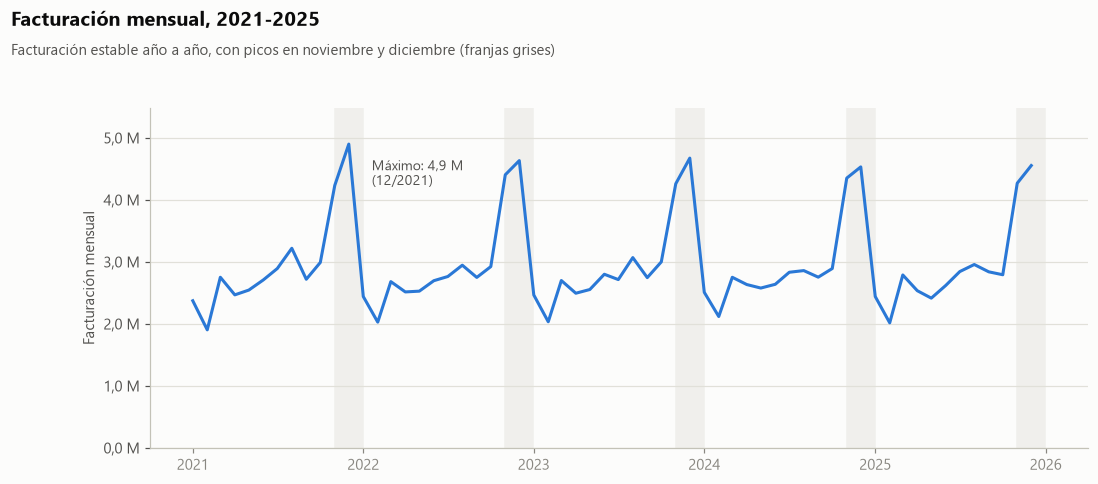

,Facturación,Pedidos
order_date,,
2021,"35,7 M",27.554
2022,"35,3 M",27.564
2023,"35,5 M",27.632
2024,"35,5 M",27.768
2025,"35,1 M",27.598


Media mensual nov-dic: 4,5 M  |  resto del año: 2,6 M


In [4]:
mensual = ventas.set_index("order_date")["net_sales"].resample("MS").sum()

fig, ax = plt.subplots(figsize=(11, 4.6))

# Franjas grises en noviembre-diciembre de cada año
for anio in mensual.index.year.unique():
    ax.axvspan(pd.Timestamp(f"{anio}-11-01"), pd.Timestamp(f"{anio}-12-31"), color=FRANJA, zorder=0)

ax.plot(mensual.index, mensual.values, color=AZUL, linewidth=2)

# Etiqueta solo en el valor máximo (etiquetar todos los puntos sería ilegible)
mes_max = mensual.idxmax()
ax.annotate(f"Máximo: {millones(mensual.max())}\n({mes_max:%m/%Y})",
            xy=(mes_max, mensual.max()), xytext=(15, -10), textcoords="offset points",
            fontsize=9, color=TEXTO_SUAVE, va="top")

ax.set_ylim(0, mensual.max() * 1.12)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(millones))
ax.set_ylabel("Facturación mensual")
ax.grid(axis="x", visible=False)
titulo(fig, "Facturación mensual, 2021-2025",
       "Facturación estable año a año, con picos en noviembre y diciembre (franjas grises)")
plt.show()

# Tabla de apoyo: facturación anual y media por mes del año
anual = ventas.groupby(ventas["order_date"].dt.year)["net_sales"].agg(["sum", "count"])
anual.columns = ["Facturación", "Pedidos"]
display(formatear(anual, {"Facturación": millones, "Pedidos": miles}))

media_mes = mensual.groupby(mensual.index.month).mean()
print(f"Media mensual nov-dic: {millones(media_mes[[11, 12]].mean())}  |  "
      f"resto del año: {millones(media_mes.drop([11, 12]).mean())}")

**Lectura:**
- La facturación anual es **muy estable** (unos 35,5 M al año) y no muestra crecimiento ni caída entre 2021 y 2025.
- Hay una **estacionalidad muy marcada**: noviembre y diciembre (Black Friday y Navidad) facturan casi el **doble** que la media del resto de meses. Febrero es el mes más flojo.

**En Power BI:** gráfico de líneas con jerarquía año → trimestre → mes de `dim_fecha`, una tarjeta con la variación respecto al año anterior y un gráfico de "media por mes del año" para aislar la estacionalidad.

### Gráfica 2 · Facturación y margen por categoría de producto

**Pregunta:** ¿qué categorías aportan más ventas? ¿Las que más venden son también las más rentables?

**Cómo se construye:**
1. Unimos `items` con `productos` para saber la categoría de cada línea vendida.
2. Por categoría, sumamos facturación y beneficio y calculamos el **margen** (beneficio / facturación).
3. Facturación (millones) y margen (%) tienen escalas distintas, así que se muestran en **dos paneles** que comparten el mismo orden de categorías: así se puede leer cada fila de izquierda a derecha.
4. Barras **horizontales** porque los nombres de categoría son largos y se leen mejor en vertical.

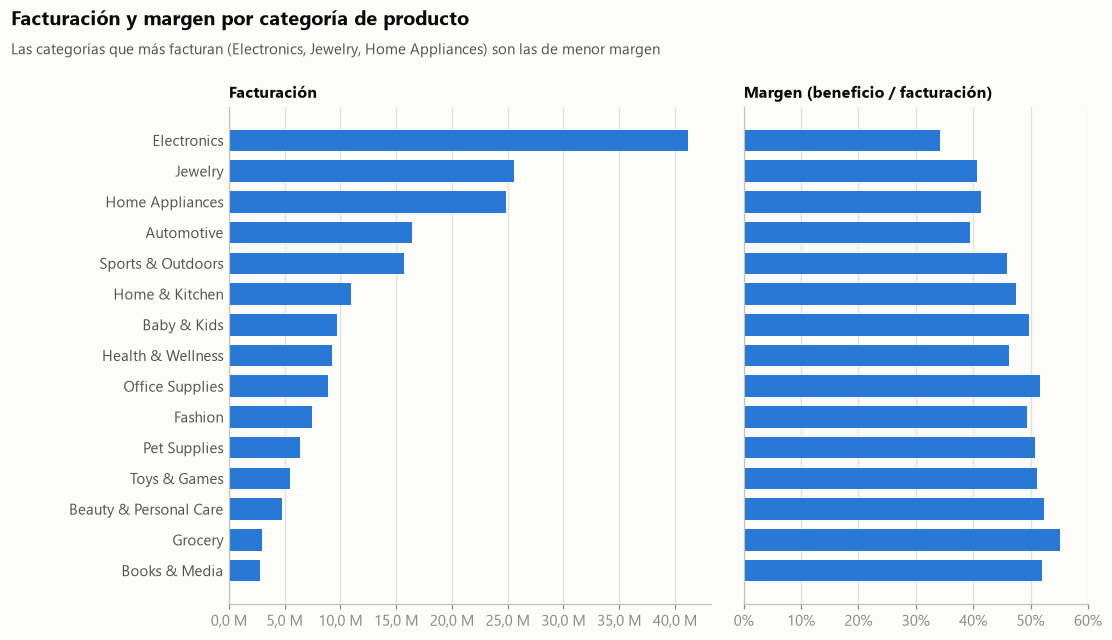

,net_sales,profit,margen_pct,peso_pct
product_category,,,,
Electronics,"41,1 M","14,1 M","34,3 %","21,4 %"
Jewelry,"25,6 M","10,4 M","40,7 %","13,3 %"
Home Appliances,"24,8 M","10,3 M","41,4 %","12,9 %"
Automotive,"16,4 M","6,5 M","39,4 %","8,5 %"
Sports & Outdoors,"15,7 M","7,2 M","46,0 %","8,2 %"
Home & Kitchen,"11,0 M","5,2 M","47,4 %","5,7 %"
Baby & Kids,"9,7 M","4,8 M","49,7 %","5,0 %"
Health & Wellness,"9,2 M","4,3 M","46,2 %","4,8 %"
Office Supplies,"8,9 M","4,6 M","51,6 %","4,6 %"


In [5]:
items_cat = items.merge(productos[["product_id", "product_category"]], on="product_id", how="left")

por_categoria = items_cat.groupby("product_category")[["net_sales", "profit"]].sum()
por_categoria["margen_pct"] = por_categoria["profit"] / por_categoria["net_sales"] * 100
por_categoria = por_categoria.sort_values("net_sales")      # de menor a mayor: la mayor queda arriba

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 6.2), sharey=True,
                               gridspec_kw={"width_ratios": [1.4, 1]})

ax1.barh(por_categoria.index, por_categoria["net_sales"], color=AZUL, height=0.7)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(millones))
ax1.set_title("Facturación", fontsize=10.5)

ax2.barh(por_categoria.index, por_categoria["margen_pct"], color=AZUL, height=0.7)
ax2.set_xlim(0, 60)
ax2.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax2.set_title("Margen (beneficio / facturación)", fontsize=10.5)

for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)

titulo(fig, "Facturación y margen por categoría de producto",
       "Las categorías que más facturan (Electronics, Jewelry, Home Appliances) son las de menor margen")
fig.subplots_adjust(left=0.19, wspace=0.08)       # margen izquierdo para los nombres largos
plt.show()

tabla = por_categoria.sort_values("net_sales", ascending=False)
tabla["peso_pct"] = tabla["net_sales"] / tabla["net_sales"].sum() * 100
display(formatear(tabla, {"net_sales": millones, "profit": millones,
                          "margen_pct": pct, "peso_pct": pct}))

**Lectura:**
- **Electronics** es con diferencia la categoría que más factura (alrededor de un 21% del total), seguida de Jewelry y Home Appliances.
- Existe una **relación inversa entre volumen y margen**: Electronics tiene el margen más bajo (≈34%), mientras que categorías pequeñas como Grocery o Books & Media superan el 50%.
- Implicación de negocio: las categorías grandes aportan volumen, pero las pequeñas son más rentables por cada unidad vendida.

**En Power BI:** gráfico de barras con jerarquía categoría → subcategoría → marca (`dim_productos`), y un gráfico de dispersión facturación frente a margen con una burbuja por categoría.

### Gráfica 3 · Facturación y ticket medio por país

**Pregunta:** ¿de dónde viene la facturación? ¿Los clientes de algunos países gastan más por pedido?

**Cómo se construye:**
1. El país está en `dim_clientes`, así que unimos `ventas` con `clientes` por `customer_id`.
2. Por país calculamos la facturación total y el **ticket medio** (facturación media por pedido).
3. De nuevo dos paneles con el mismo orden de países, porque son dos medidas con escalas distintas.
4. Las barras del ticket medio empiezan en 0: las diferencias entre países son reales pero moderadas, y un eje recortado las exageraría.

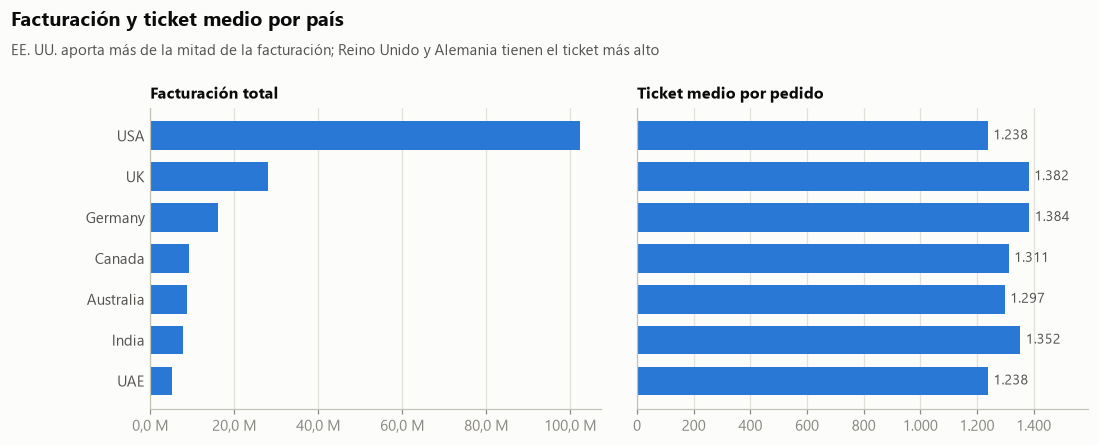

,facturacion,ticket_medio,pedidos,peso_pct
customer_country,,,,
USA,"102,2 M",1.238,82.600,"57,7 %"
UK,"28,0 M",1.382,20.235,"15,8 %"
Germany,"16,0 M",1.384,11.593,"9,1 %"
Canada,"9,2 M",1.311,7.015,"5,2 %"
Australia,"8,8 M",1.297,6.794,"5,0 %"
India,"7,7 M",1.352,5.707,"4,4 %"
UAE,"5,2 M",1.238,4.172,"2,9 %"


In [6]:
ventas_cli = ventas.merge(clientes[["customer_id", "customer_country", "customer_segment"]],
                          on="customer_id", how="left")

por_pais = ventas_cli.groupby("customer_country")["net_sales"].agg(facturacion="sum", ticket_medio="mean",
                                                                   pedidos="count")
por_pais = por_pais.sort_values("facturacion")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)

ax1.barh(por_pais.index, por_pais["facturacion"], color=AZUL, height=0.7)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(millones))
ax1.set_title("Facturación total", fontsize=10.5)

ax2.barh(por_pais.index, por_pais["ticket_medio"], color=AZUL, height=0.7)
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(miles))
ax2.set_title("Ticket medio por pedido", fontsize=10.5)

# Valor al final de cada barra del ticket medio: aquí las diferencias son pequeñas y conviene leerlas
for y, valor in enumerate(por_pais["ticket_medio"]):
    ax2.text(valor + 20, y, miles(valor), va="center", fontsize=9, color=TEXTO_SUAVE)
ax2.set_xlim(0, por_pais["ticket_medio"].max() * 1.15)

for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)

titulo(fig, "Facturación y ticket medio por país",
       "EE. UU. aporta más de la mitad de la facturación; Reino Unido y Alemania tienen el ticket más alto")
fig.subplots_adjust(wspace=0.08)
plt.show()

tabla = por_pais.sort_values("facturacion", ascending=False)
tabla["peso_pct"] = tabla["facturacion"] / tabla["facturacion"].sum() * 100
display(formatear(tabla, {"facturacion": millones, "ticket_medio": miles,
                          "pedidos": miles, "peso_pct": pct}))

**Lectura:**
- **EE. UU. concentra cerca del 58% de la facturación**; Reino Unido es el segundo mercado (≈16%). El resto de países aporta entre un 3% y un 9% cada uno.
- El **ticket medio es más alto en Reino Unido y Alemania** (≈1.380) que en EE. UU. y Emiratos (≈1.240): son mercados más pequeños pero con pedidos de mayor importe.

**En Power BI:** un mapa con burbujas por país (tamaño = facturación) y desglose por `customer_state` y `region` al hacer clic en un país.

### Gráfica 4 · Concentración de la facturación en los clientes (curva de Pareto)

**Pregunta:** ¿el negocio depende de unos pocos clientes muy grandes? Es la conocida **regla 80/20**: en muchos negocios, el 20% de los clientes genera el 80% de las ventas.

**Cómo se construye:**
1. Sumamos la facturación de cada cliente y los ordenamos de mayor a menor.
2. Calculamos el **acumulado**: qué porcentaje de la facturación suman el primer cliente, los dos primeros, los tres primeros...
3. En el eje horizontal va el % de clientes y en el vertical el % de facturación acumulada.

**Cómo se lee:** cuanto más se "pega" la curva a la esquina superior izquierda, más concentrada está la facturación. La **diagonal gris** representa el caso de reparto perfectamente igualitario (todos los clientes facturan lo mismo).

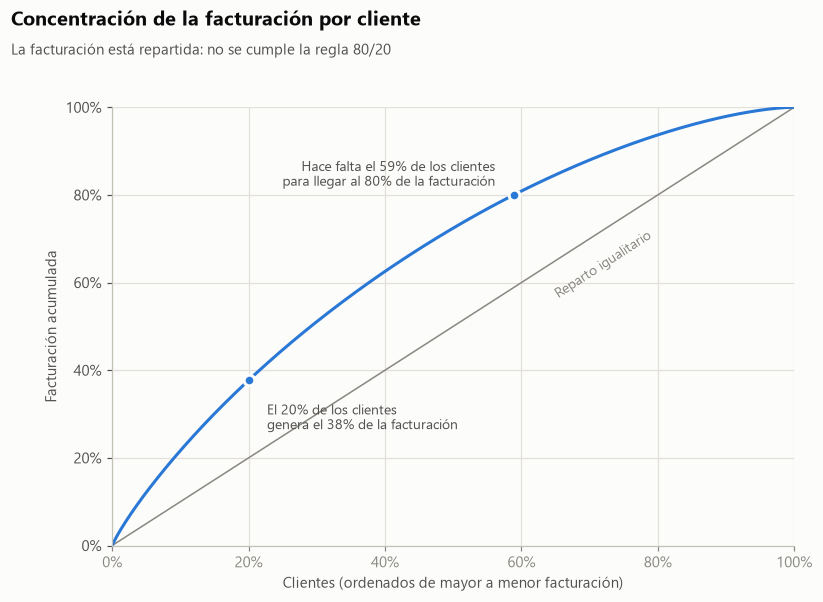

,clientes,facturacion,ticket_medio,facturacion_por_cliente
customer_segment,,,,
Consumer,13.585,"97,2 M",1.285,7.155
Premium,6.275,"44,3 M",1.274,7.055
VIP,2.536,"17,9 M",1.283,7.060
Business,2.515,"17,8 M",1.289,7.062


In [7]:
por_cliente = ventas.groupby("customer_id")["net_sales"].sum().sort_values(ascending=False)

pct_clientes    = np.arange(1, len(por_cliente) + 1) / len(por_cliente) * 100
pct_facturacion = por_cliente.cumsum().values / por_cliente.sum() * 100

# Dos puntos de referencia: qué factura el 20% superior y cuántos clientes hacen falta para llegar al 80%
fact_top20     = pct_facturacion[int(len(por_cliente) * 0.2) - 1]
clientes_80pct = pct_clientes[np.argmax(pct_facturacion >= 80)]

fig, ax = plt.subplots(figsize=(8, 5.6))
ax.plot([0, 100], [0, 100], color=GRIS, linewidth=1)                      # reparto igualitario
ax.plot(pct_clientes, pct_facturacion, color=AZUL, linewidth=2)

for x, y, texto, desplaz, alineacion in [
        (20, fact_top20, f"El 20% de los clientes\ngenera el {fact_top20:.0f}% de la facturación", (12, -32), "left"),
        (clientes_80pct, 80, f"Hace falta el {clientes_80pct:.0f}% de los clientes\npara llegar al 80% de la facturación", (-12, 6), "right")]:
    ax.plot(x, y, "o", color=AZUL, markersize=7, markeredgecolor=FONDO, markeredgewidth=2)
    ax.annotate(texto, xy=(x, y), xytext=desplaz, textcoords="offset points", fontsize=9,
                color=TEXTO_SUAVE, ha=alineacion)

ax.text(72, 64, "Reparto igualitario", rotation=33, fontsize=9, color=GRIS, ha="center", va="center")
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Clientes (ordenados de mayor a menor facturación)")
ax.set_ylabel("Facturación acumulada")
titulo(fig, "Concentración de la facturación por cliente",
       "La facturación está repartida: no se cumple la regla 80/20")
plt.show()

# Tabla de apoyo: ¿gastan más los clientes de los segmentos superiores?
seg = ventas_cli.groupby("customer_segment").agg(clientes=("customer_id", "nunique"),
                                                 facturacion=("net_sales", "sum"),
                                                 ticket_medio=("net_sales", "mean"))
seg["facturacion_por_cliente"] = seg["facturacion"] / seg["clientes"]
display(formatear(seg.sort_values("facturacion", ascending=False),
                  {"clientes": miles, "facturacion": millones,
                   "ticket_medio": miles, "facturacion_por_cliente": miles}))

**Lectura:**
- La facturación está **poco concentrada**: el 20% de los mejores clientes genera solo alrededor del 38% de las ventas, y hace falta casi el **60% de los clientes** para llegar al 80%. El negocio no depende de un grupo pequeño de grandes compradores, lo que reduce el riesgo de perder ingresos si se va algún cliente.
- La tabla por segmento muestra algo llamativo: un cliente **VIP o Premium factura lo mismo que uno Consumer** (≈7.100 en el periodo) y su ticket medio es igual. La segmentación actual no refleja diferencias reales de gasto, algo que merece revisarse en el análisis profundo.

**En Power BI:** una tabla de clientes ordenada por facturación con la medida de % acumulado (DAX), y una comparativa de segmentos y rangos de edad (`rango_edad`).

### Gráfica 5 · Días de entrega y valoración del cliente

**Pregunta:** ¿los clientes valoran peor los pedidos que tardan más en llegar?

**Cómo se construye:**
1. Solo los pedidos **completados** tienen días de entrega y valoración (los demás tienen esos campos vacíos, como vimos en el ETL). `groupby` ignora los vacíos automáticamente.
2. Calculamos la valoración media para cada número de días de entrega (0 a 14).
3. Usamos **línea con puntos** porque los días son una escala ordenada. Al no ser barras, el eje vertical puede empezar en 3 en lugar de 0 para que se aprecien las diferencias. Esas diferencias se leen sobre una escala de 1 a 5, así que una caída de 0,5 puntos es importante.
4. La línea gris horizontal marca la valoración media global como referencia.

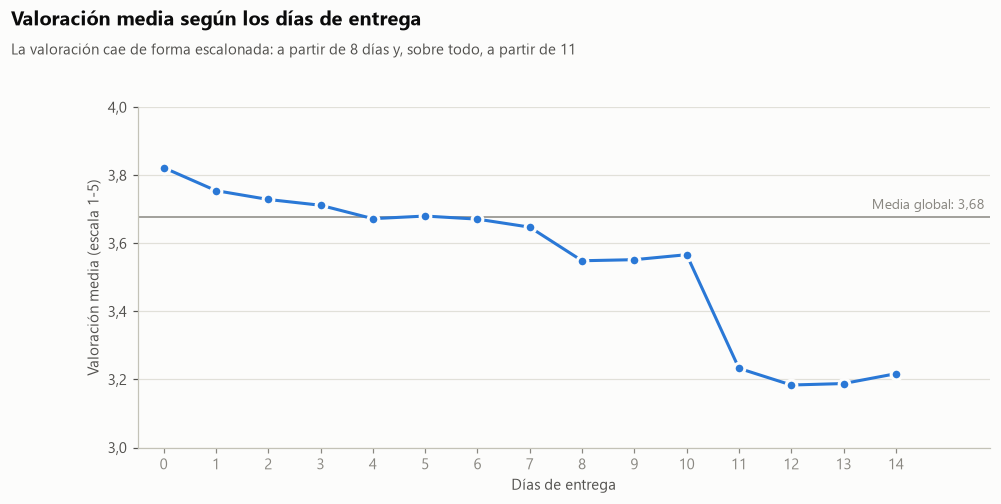

,valoracion,pedidos
delivery_status,,
Early,4.02,9.757
On Time,3.73,86.916
Delayed,3.22,16.886


In [8]:
por_dias = ventas.groupby("delivery_days").agg(valoracion=("customer_rating", "mean"),
                                               pedidos=("order_id", "count"))
media_global = ventas["customer_rating"].mean()

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.axhline(media_global, color=GRIS, linewidth=1)
ax.text(15.7, media_global + 0.015, f"Media global: {media_global:.2f}".replace(".", ","),
        ha="right", va="bottom", fontsize=9, color=GRIS)

ax.plot(por_dias.index, por_dias["valoracion"], color=AZUL, linewidth=2,
        marker="o", markersize=7, markeredgecolor=FONDO, markeredgewidth=2)

ax.set_xticks(range(0, 15))
ax.set_ylim(3.0, 4.0)
ax.set_xlim(-0.5, 15.8)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:.1f}".replace(".", ",")))
ax.set_xlabel("Días de entrega")
ax.set_ylabel("Valoración media (escala 1-5)")
ax.grid(axis="x", visible=False)
titulo(fig, "Valoración media según los días de entrega",
       "La valoración cae de forma escalonada: a partir de 8 días y, sobre todo, a partir de 11")
plt.show()

# Tabla de apoyo: valoración según el estado de la entrega (respecto al plazo prometido)
estado = ventas.groupby("delivery_status").agg(valoracion=("customer_rating", "mean"),
                                               pedidos=("order_id", "count")).dropna()
display(formatear(estado.sort_values("valoracion", ascending=False), {"valoracion": "{:.2f}", "pedidos": miles}))

**Lectura:**
- Existe una **relación clara**: los pedidos entregados en el día se valoran con ≈3,8, mientras que a partir de **11 días** la nota baja a ≈3,2.
- La caída no es gradual sino **por escalones** (de 0 a 7 días, de 8 a 10 y de 11 en adelante), lo que sugiere umbrales de paciencia del cliente.
- Lo que más pesa es **cumplir el plazo prometido**: los pedidos que llegan antes de lo previsto (*Early*) se valoran con ≈4,0 y los que llegan tarde (*Delayed*) con ≈3,2.

**En Power BI:** análisis por `shipping_method` y `warehouse`, y una medida de % de entregas a tiempo como indicador logístico.

### Gráfica 6 · Facturación por canal de captación

**Pregunta:** ¿a través de qué canales de marketing llegan las ventas?

**Cómo se construye:**
1. Agrupamos `ventas` por `marketing_channel` y sumamos la facturación.
2. Barras horizontales ordenadas de mayor a menor (*ranking*), un solo color.
3. La tabla de apoyo incluye el número de pedidos y el ticket medio para saber si un canal factura más **porque trae más pedidos o porque son pedidos más caros**.

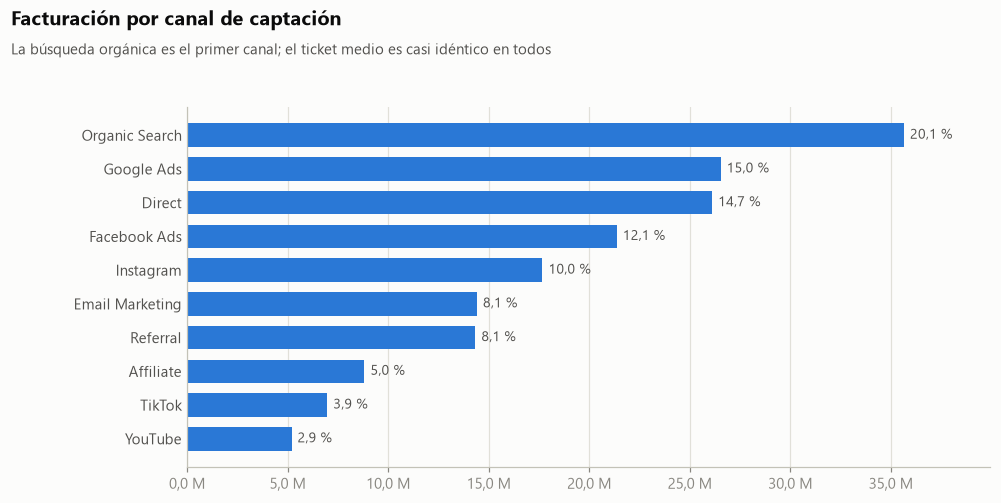

,facturacion,pedidos,ticket_medio,peso_pct
marketing_channel,,,,
Organic Search,"35,7 M",27.742,1.285,"20,1 %"
Google Ads,"26,5 M",20.633,1.286,"15,0 %"
Direct,"26,1 M",20.515,1.273,"14,7 %"
Facebook Ads,"21,4 M",16.651,1.284,"12,1 %"
Instagram,"17,7 M",13.801,1.281,"10,0 %"
Email Marketing,"14,4 M",11.218,1.285,"8,1 %"
Referral,"14,3 M",11.191,1.282,"8,1 %"
Affiliate,"8,8 M",6.848,1.289,"5,0 %"
TikTok,"7,0 M",5.437,1.284,"3,9 %"


In [9]:
por_canal = ventas.groupby("marketing_channel")["net_sales"].agg(facturacion="sum", pedidos="count",
                                                                 ticket_medio="mean")
por_canal["peso_pct"] = por_canal["facturacion"] / por_canal["facturacion"].sum() * 100
por_canal = por_canal.sort_values("facturacion")

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(por_canal.index, por_canal["facturacion"], color=AZUL, height=0.7)

# Porcentaje sobre el total al final de cada barra
for y, (valor, peso) in enumerate(zip(por_canal["facturacion"], por_canal["peso_pct"])):
    ax.text(valor + 3e5, y, f"{peso:.1f} %".replace(".", ","), va="center", fontsize=9, color=TEXTO_SUAVE)

ax.set_xlim(0, por_canal["facturacion"].max() * 1.12)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(millones))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
titulo(fig, "Facturación por canal de captación",
       "La búsqueda orgánica es el primer canal; el ticket medio es casi idéntico en todos")
fig.subplots_adjust(left=0.17)
plt.show()

display(formatear(por_canal.sort_values("facturacion", ascending=False),
                  {"facturacion": millones, "pedidos": miles,
                   "ticket_medio": miles, "peso_pct": pct}))

**Lectura:**
- **Organic Search** (búsqueda orgánica) es el canal que más factura (≈20%), seguido de Google Ads y el tráfico directo. Los canales de vídeo (TikTok, YouTube) son los más pequeños.
- El **ticket medio es prácticamente igual en todos los canales** (≈1.270-1.290): las diferencias de facturación se deben solo al **número de pedidos** que trae cada canal, no a que unos atraigan compras más caras.
- Para valorar la rentabilidad de cada canal faltaría su coste (inversión en publicidad), que no está en el dataset.

**En Power BI:** cruce de canal con `campaign_name` y uso de cupones (`tiene_cupon`), y evolución mensual de cada canal.

## 4. Resumen de hallazgos y propuesta para Power BI

| # | Hallazgo principal | Página propuesta en Power BI |
|---|---|---|
| 1 | Ventas estables (~35,5 M/año) con fuerte estacionalidad en noviembre-diciembre | **Resumen y evolución**: KPI + línea temporal |
| 2 | Electronics lidera en ventas pero tiene el menor margen; las categorías pequeñas son más rentables | **Productos**: categoría → subcategoría → marca |
| 3 | EE. UU. ≈ 58% de las ventas; Reino Unido y Alemania con mayor ticket medio | **Mercados**: mapa y detalle por país/estado |
| 4 | Facturación poco concentrada; los segmentos VIP/Premium no gastan más que Consumer | **Clientes**: Pareto, segmentos, edades |
| 5 | La valoración cae con entregas largas y, sobre todo, con retrasos sobre el plazo | **Logística y satisfacción**: plazos, almacenes, métodos de envío |
| 6 | Organic Search es el primer canal; el ticket es igual en todos los canales | **Marketing**: canales, campañas, cupones |

**Ideas para el análisis profundo:**
- Filtrar por `order_status` para separar la facturación real (pedidos completados) de la potencial.
- Estudiar los motivos de devolución (`return_reason`) por categoría de producto.
- Revisar por qué la segmentación de clientes no se traduce en diferencias de gasto.
- Recordar la limitación del ETL: en un 8% de los pedidos la cabecera no cuadra con sus líneas, así que las cifras por producto (gráfica 2) y las cifras por pedido no suman exactamente lo mismo.